# Laboratory 2 (Part III)

In [111]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from astropy.io import fits
from astropy import coordinates as coord, units as u
from astropy.time import Time, TimeDelta
import pickle
import jplephem

Load bias and flat files

In [112]:
median_bias = pickle.load(open('median_bias.p','rb'))
median_bias_error = pickle.load(open('median_bias_errors.p','rb'))
median_normalized_flat = pickle.load(open('median_normalized_flat.p','rb'))
median_normalized_flat_error = pickle.load(open('median_normalized_flat_errors.p','rb'))

Load list of fits science files and select a test list (10 elements)

In [113]:
science_list = np.genfromtxt('group09_HAT-P-12_20200422/science/science.list', dtype='str')
print(np.shape(science_list))

science_test_list = science_list[1100:1110]
np.shape(science_test_list)

(2611,)


(10,)

For each frame in test list:
- open scientific frame
- multiply by gain
- subtract the median bias
- divide by the median normalized flat field
- save data and error in "correct" folder

In [114]:
for science_name in science_test_list:
    science_fits = fits.open('group09_HAT-P-12_20200422/science/' + science_name)
    ron = science_fits[0].header['RDNOISE']
    gain = science_fits[0].header['GAIN']

    # convert adu to electronsm no error propagation bc gain is constant
    science_data = science_fits[0].data * gain 

    # subtract bias and propagate error (ron, poisson and median bias)
    science_debiased = science_data - median_bias
    science_debiased_error = np.sqrt(ron**2 + np.sqrt(science_debiased)**2 + median_bias_error**2)
    
    # normalize data and propagate error
    science_corrected = science_debiased / median_normalized_flat
    science_corrected_error = np.sqrt((science_debiased_error/science_debiased)**2 + (median_normalized_flat_error/median_normalized_flat)**2)

    # science_frame / > AF#####.fits
    new_name =  'group09_HAT-P-12_20200422/correct/' + science_name[:-5] + '_corr.p'
    # print(f'Original name: {science_name:s} new_name: {new_name:s}')
    pickle.dump(science_corrected,open(new_name,'wb'))
    
    new_name =  'group09_HAT-P-12_20200422/correct/' + science_name[:-5] + '_corr_error.p'
    # print(f'Original name: {science_name:s} new_name: {new_name:s}')
    pickle.dump(science_corrected_error,open(new_name,'wb'))



/tmp/ipykernel_6801/3325573375.py:11: RuntimeWarning: invalid value encountered in sqrt
  science_debiased_error = np.sqrt(ron**2 + np.sqrt(science_debiased)**2 + median_bias_error**2)
/tmp/ipykernel_6801/3325573375.py:14: RuntimeWarning: divide by zero encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_6801/3325573375.py:14: RuntimeWarning: invalid value encountered in divide
  science_corrected = science_debiased / median_normalized_flat
/tmp/ipykernel_6801/3325573375.py:15: RuntimeWarning: divide by zero encountered in divide
  science_corrected_error = np.sqrt((science_debiased_error/science_debiased)**2 + (median_normalized_flat_error/median_normalized_flat)**2)


Retrieve properties from the fits header:
- Julian day
- exposure time
- airmass

In [115]:
n_images = len(science_test_list)

array_jd = np.zeros(n_images)
array_exptime = np.zeros(n_images)
array_airmass = np.zeros(n_images)

for i_science, science_name in enumerate(science_test_list):
    science_fits = fits.open('group09_HAT-P-12_20200422/science/' +  science_name)
    array_jd[i_science] = science_fits[0].header['JD']
    array_exptime[i_science] = science_fits[0].header['EXPTIME']
    array_airmass[i_science] = science_fits[0].header['AIRMASS']

    if i_science == 0:
        print(f"{array_exptime[i_science]:12.4f} : {science_fits[0].header.comments['EXPTIME']:s}")
        print(f"{array_jd[i_science]:12.4f} : {science_fits[0].header.comments['JD']:s}, scale {science_fits[0].header['TIMESYS']:s}")
        print(f"{science_fits[0].header['SITELONG']:12.4f} : {science_fits[0].header.comments['SITELONG']:s}")
        print(f"{science_fits[0].header['SITELAT']:12.4f} : {science_fits[0].header.comments['SITELAT']:s}")
        print(f"{science_fits[0].header['SITEELEV']:12.4f} : {science_fits[0].header.comments['SITEELEV']:s}")

        print(f"{science_fits[0].header['OBJCTRA']:12s} : {science_fits[0].header.comments['OBJCTRA']:s}")
        print(f"{science_fits[0].header['OBJCTDEC']:12s} : {science_fits[0].header.comments['OBJCTDEC']:s}")

        telescope_longitude = science_fits[0].header['SITELONG']
        telescope_latitude = science_fits[0].header['SITELAT']
        telescope_elevation = science_fits[0].header['SITEELEV']
        telescope_ra = science_fits[0].header['OBJCTRA']
        telescope_dec = science_fits[0].header['OBJCTDEC']

      4.0000 : [s] Exposure time
2458962.4421 : JD at start, scale UTC
     11.5690 : [deg] Telescope longitude, E11:34:08.397
     45.8486 : [deg] Telescope latitude, N45:50:54.894
   1376.2000 : [m] Telescope height above sea level
13:57:33.28  : Object RA (J2000.0)
+43:29:35    : Object DEC (J2000.0)


## Analysis of the first test image

In [116]:
print(array_jd)
print(telescope_longitude)
print(telescope_latitude)
print(telescope_elevation)

[2458962.442096 2458962.442166 2458962.442235 2458962.442304
 2458962.442374 2458962.442443 2458962.442513 2458962.442583
 2458962.442652 2458962.442722]
11.5689993
45.8485832
1376.2


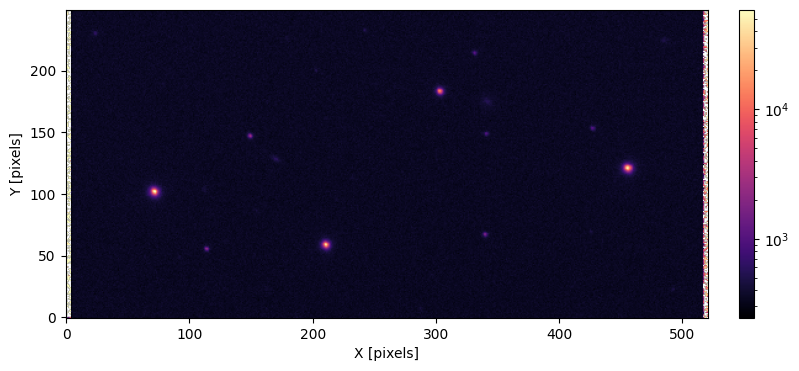

In [117]:
science_frame_name = 'group09_HAT-P-12_20200422/correct/' + science_test_list[0][:-5] + '_corr.p' #remove fits extension and add corr.p
# print(science_frame_name)
science_corrected = pickle.load(open(science_frame_name, 'rb'))

vmin = np.amin(science_corrected[:,15:-15])
vmax = np.amax(science_corrected[:,15:-15])

fig, ax = plt.subplots(1,figsize=(10,4))
im1 = plt.imshow(science_corrected,cmap=plt.colormaps['magma'], norm=colors.LogNorm(vmin=vmin, vmax=vmax), origin='lower')
plt.colorbar(im1, ax=ax, fraction=0.05, pad=0.04)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
plt.show()

Define function to plot circle around star

In [118]:
def make_circle_around_star(x_pos, y_pos, radius, thickness, label, color='C0', alpha=0.5):
    from matplotlib.patches import Circle
    n, radii = 50, [radius, radius+thickness]
    theta = np.linspace(0,2*np.pi,n, endpoint=True)
    xs = np.outer(radii, np.cos(theta))
    ys = np.outer(radii, np.sin(theta))

    xs[1,:] = xs[1,::-1]
    ys[1,:] = ys[1,::-1]
    ax.fill(np.ravel(xs+x_pos), np.ravel(ys+y_pos),edgecolor=None,facecolor=color,alpha=alpha,label=label)

Plot circle around star with initial guess of coordinates and radius

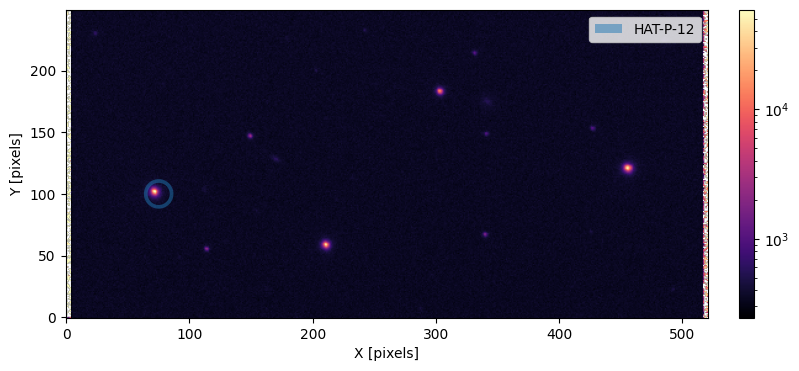

In [119]:
x_target = 75
y_target = 100

fig, ax = plt.subplots(figsize=(10,4))
im1 = plt.imshow(science_corrected,cmap=plt.colormaps['magma'],norm=colors.LogNorm(vmin=vmin, vmax=vmax),origin='lower')
make_circle_around_star(x_target, y_target, radius=9, thickness=3, label='HAT-P-12')
plt.colorbar(im1,ax=ax,fraction=0.05,pad=0.04)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
ax.legend()
plt.show()

From Simbad site, HAT-P-12 properties:
- coord (ICRS) 13 57 33.4668726399 +43 29 36.601508739
- proper motion -134.793 -44.229 mas/yr
- parallax 7.0448 mas
- radial velocity -40.806702 km/s

In [120]:
observatory = coord.EarthLocation.from_geodetic(
    lon = telescope_longitude * u.deg,
    lat = telescope_latitude * u.deg,
    height = telescope_elevation * u.m
)

target_j2000 = coord.SkyCoord(
    '13:57:33.47', '+43:29:36.60',
    unit = (u.hourangle, u.deg),
    frame = 'icrs',
    obstime = Time('J2000'),
    pm_ra_cosdec = -134.793 * u.mas/u.yr,
    pm_dec = -44.229 * u.mas/u.yr,
    distance = (7.0448 * u.mas).to(u.pc, equivalencies = u.parallax()),
    radial_velocity = -40.806702 * u.km/u.s
)

Compute and plot light travel time. When LTT is negative you are further away from target, when positive you are closer.

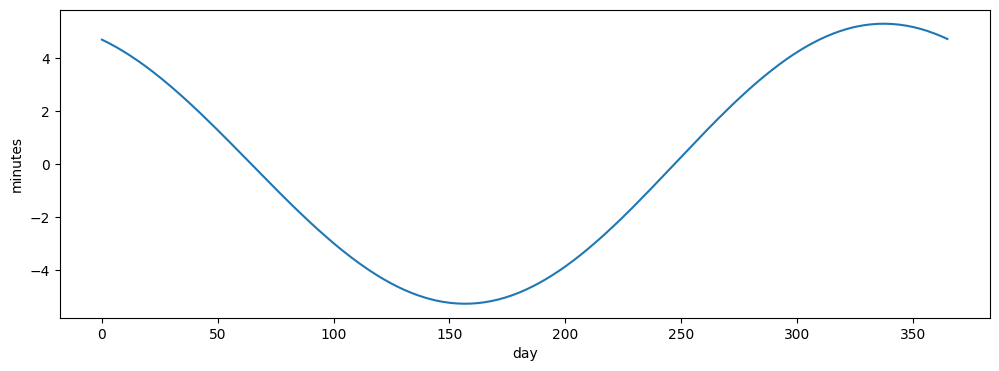

In [121]:
reference_epoch = Time(array_jd[0], format='jd', scale='utc', location=observatory)
target = target_j2000.apply_space_motion(new_obstime=reference_epoch)

jd_plot = np.arange(array_jd[0], array_jd[0]+365.25, 0.25)
tm_plot = Time(jd_plot, format='jd', scale='utc', location=observatory)
llt_plot = tm_plot.light_travel_time(target, kind='barycentric')        #light travel time

fig, ax = plt.subplots(figsize=(12,4))
ax.plot(jd_plot - array_jd[0], llt_plot.to_value(u.min))
ax.set_ylabel('minutes')
ax.set_xlabel('day')
plt.show()

Convert from Julian time to barycentric dynamical time (BJD -> TDB).

In [122]:
tm_start = Time(array_jd, format='jd', scale='utc', location=observatory)
tm = tm_start + TimeDelta(array_exptime/2. * u.s)
# print(tm_start.to_value('iso'))
# print(tm.to_value('iso'))

llt_bary = tm.light_travel_time(target, kind='barycentric')
bjd_tdb = tm.tdb + llt_bary

Identify the photocenter of our target, using the average position of the flux of our star.

First, 3d plot of the target.

(521,) (250,)
(250, 521) (250, 521)


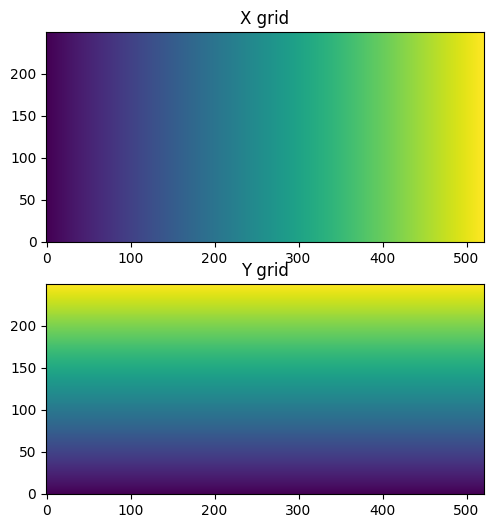

In [123]:
ylen, xlen = np.shape(science_corrected)
X_axis = np.arange(0, xlen, 1)
Y_axis = np.arange(0, ylen, 1)

X, Y = np.meshgrid(X_axis, Y_axis)

print(np.shape(X_axis), np.shape(Y_axis))
print(np.shape(X), np.shape(Y))

fig, ax = plt.subplots(2, figsize=(6,6))
ax[0].imshow(X, origin='lower')
ax[1].imshow(Y, origin='lower')
ax[0].set_title('X grid')
ax[1].set_title('Y grid')
plt.show()

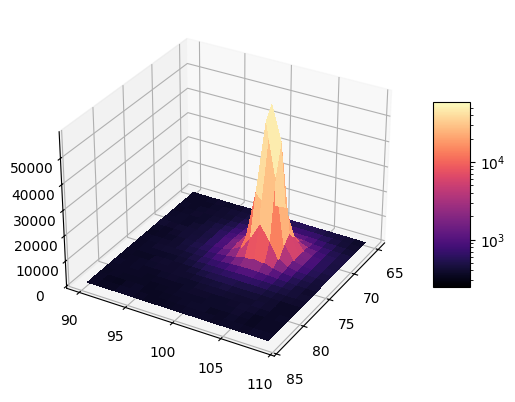

In [124]:
radius_plot = 10

fig, ax = plt.subplots(subplot_kw={'projection':'3d'})
surf = ax.plot_surface(
    X[y_target - radius_plot:y_target+radius_plot, x_target-radius_plot:x_target+radius_plot], 
    Y[y_target - radius_plot:y_target+radius_plot, x_target-radius_plot:x_target+radius_plot], 
    science_corrected[y_target-radius_plot:y_target+radius_plot, x_target-radius_plot:x_target+radius_plot], 
    cmap=plt.colormaps['magma'],
    norm = colors.LogNorm(vmin=vmin, vmax=vmax),
    lw=0, antialiased=False)

ax.azim = 30
ax.elev = 30
fig.colorbar(surf, shrink=.5,aspect=5)
plt.show()

Define photocenter and compute

$$x_{photocenter} = \frac{\sum F_i x_i}{\sum F_i}$$

72.6811471267489 101.37742492208325


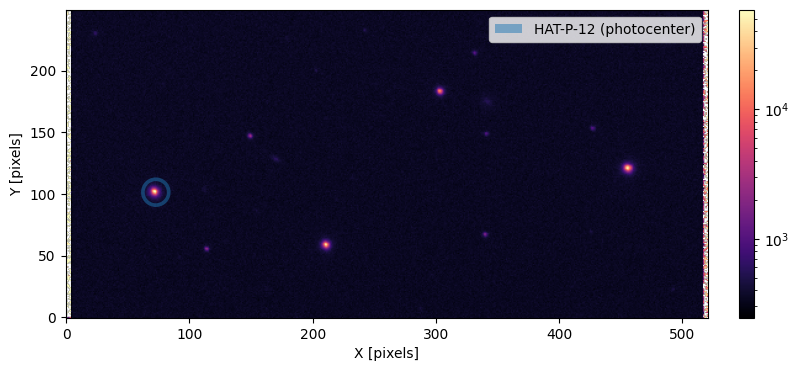

In [125]:
target_distance = np.sqrt((X - x_target)**2 + (Y - y_target)**2)
selection = target_distance < 15

x_photocenter = np.sum(X[selection] * science_corrected[selection]) / np.sum(science_corrected[selection])
y_photocenter = np.sum(Y[selection] * science_corrected[selection]) / np.sum(science_corrected[selection])
print(x_photocenter, y_photocenter)

fig, ax = plt.subplots(figsize=(10,4))
im1 = plt.imshow(science_corrected,cmap=plt.colormaps['magma'],norm=colors.LogNorm(vmin=vmin, vmax=vmax),origin='lower')
make_circle_around_star(x_photocenter, y_photocenter, radius=9, thickness=3, label='HAT-P-12 (photocenter)')
plt.colorbar(im1,ax=ax,fraction=0.05,pad=0.04)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
ax.legend()
plt.show()

### Centroid algorithm

Other method, we will use the **weighted centroid**. We weigh the coordinates of each pixel $x_\mathrm{i}$, $y_\mathrm{i}$ according to the flux collected by that pixel $F_\mathrm{i}$. We compute the average over the pixel within a distance *inner_radius* from the centre of the target.
Following the definition of the weighted average, the average of each coordinate is equal to the weighted sums 
$\sum x_i F_i$ 
and 
$\sum y_{\mathrm{i}} F_{\mathrm{i}}$  
divided by the sum of the weights, i.e., the total flux within the *inner radius* $F = \sum F_\mathrm{i}$. Given $C$ the area within the *inner circle*:

$x = \frac{\sum_{i}^{i \in C}{x_i F_i}}{\sum_{i}^{i \in C}{F_i}} ; \qquad y = \frac{\sum_{i}^{i \in C}{y_i F_i}}{\sum_{i}^{i \in C}{F_i}}$


The **inner radius** must be large enough to include **the entirety of the flux** coming from the star, and some sky background as well. *Don't be greedy with this value!* Its value in pixels is stored in the `inner_radius` variable. We will return to the meaning of this parameter later.

You have already seen the weighted average, most likely using the inverse of the squared errors as weights. Here, you are using the same tool, with just the flux as weights.


In [126]:
inner_radius = 14

# Selection of the pixels within the inner radius
annulus_sel = (target_distance < inner_radius)

# Weighted sum of coordinates
weighted_X = np.sum(science_corrected[annulus_sel]*X[annulus_sel])
weighted_Y = np.sum(science_corrected[annulus_sel]*Y[annulus_sel])

# Sum of the weights
total_flux = np.sum(science_corrected[annulus_sel])

# Refined determination of coordinates
x_target_refined = weighted_X/total_flux
y_target_refined = weighted_Y/total_flux

print('Initial coordinates  x: {0:5.2f}   y: {1:5.2f}'.format(x_target, y_target))
print('Refined coordinates  x: {0:5.2f}   y: {1:5.2f}'.format(x_target_refined, y_target_refined))

Initial coordinates  x: 75.00   y: 100.00
Refined coordinates  x: 72.58   y: 101.43


Zoom of the target, good vs bad radius size

vmin:  260.2    vmax: 40753.1


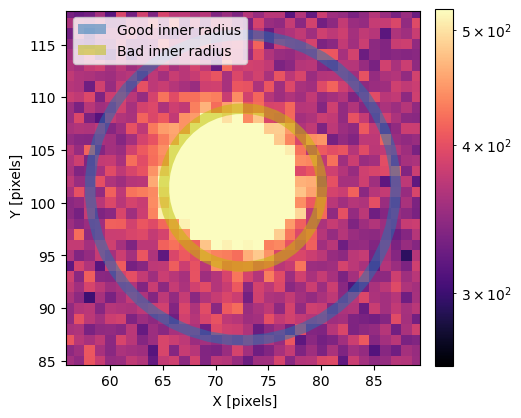

In [127]:
vmin_zoom = np.amin(science_corrected[:,100:400])
vmax_zoom = np.amax(science_corrected[:,100:400])
print('vmin:  {0:.1f}    vmax: {1:.1f}'.format(vmin_zoom, vmax_zoom))
vmax_zoom = 2*vmin_zoom

fig, ax = plt.subplots(1, figsize=(5,5))
im1 = plt.imshow(science_corrected, cmap=plt.colormaps['magma'], norm=colors.LogNorm(vmin=vmin_zoom, vmax=vmax_zoom), origin='lower')
plt.colorbar(im1,ax=ax, fraction=0.046, pad=0.04)

# Cut the plot around the target star, with some margin with respect to the inner radius
plt.xlim(x_target_refined-inner_radius*1.2, x_target_refined+inner_radius*1.2)
plt.ylim(y_target_refined-inner_radius*1.2, y_target_refined+inner_radius*1.2)

make_circle_around_star(x_target_refined, y_target_refined, inner_radius, thickness=1, label='Good inner radius')
make_circle_around_star(x_target_refined, y_target_refined, 7, thickness=1, color='y', label='Bad inner radius')

plt.xlabel(' X [pixels]')
plt.ylabel(' Y [pixels]')
plt.legend(loc='upper left')
plt.show()


Now make the algorithm iterable, iterate until the difference from the previous result is small enough.

In [128]:
# Initial coordinates of the target
x_target_initial = 75
y_target_initial = 100
print('Initial coordinates  x: {0:5.2f}   y: {1:5.2f}'.format(x_target_initial, y_target_initial))

maximum_number_of_iterations = 30

for i_iter in range(0, maximum_number_of_iterations):

    if i_iter == 0:
        x_target_previous = x_target_initial
        y_target_previous = y_target_initial
    else:
        x_target_previous = x_target_refined
        y_target_previous = y_target_refined

    target_distance = np.sqrt((X-x_target_previous)**2 + (Y-y_target_previous)**2)
    annulus_sel = (target_distance < inner_radius)
    
    weighted_X = np.sum(science_corrected[annulus_sel]*X[annulus_sel])
    weighted_Y = np.sum(science_corrected[annulus_sel]*Y[annulus_sel])
    
    total_flux = np.sum(science_corrected[annulus_sel])

    x_target_refined = weighted_X/total_flux
    y_target_refined = weighted_Y/total_flux
    
    percent_variance_x = (x_target_refined-x_target_previous)/(x_target_previous) * 100.
    percent_variance_y = (y_target_refined-y_target_previous)/(y_target_previous) * 100.
    
    print('    Iteration {0:3d}   x: {1:.3f} ({2:.2f}%)  y: {3:.3f} ({4:.2f}%)'.format(i_iter,
                                                                                   x_target_refined, 
                                                                                   percent_variance_x,
                                                                                   y_target_refined,
                                                                                   percent_variance_y))
          
    if np.abs(percent_variance_x)<0.1 and  np.abs(percent_variance_y)<0.1:
        break

print('Refined coordinates  x: {0:5.2f}   y: {1:5.2f}'.format(x_target_refined, y_target_refined))

Initial coordinates  x: 75.00   y: 100.00
    Iteration   0   x: 72.579 (-3.23%)  y: 101.434 (1.43%)
    Iteration   1   x: 71.779 (-1.10%)  y: 101.910 (0.47%)
    Iteration   2   x: 71.504 (-0.38%)  y: 102.046 (0.13%)
    Iteration   3   x: 71.419 (-0.12%)  y: 102.119 (0.07%)
    Iteration   4   x: 71.398 (-0.03%)  y: 102.145 (0.02%)
Refined coordinates  x: 71.40   y: 102.14


Plot starting center and refined center after iteration

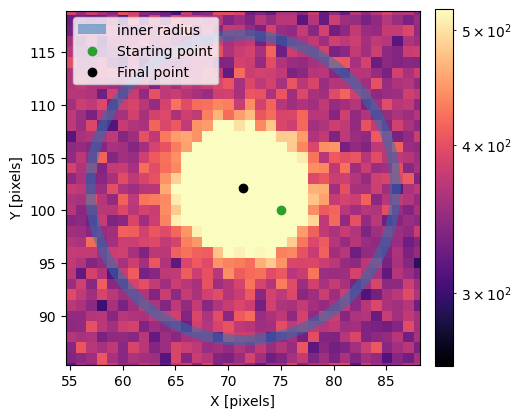

In [ ]:
fig, ax = plt.subplots(1, figsize=(5,5))
im1 = plt.imshow(science_corrected, cmap=plt.colormaps['magma'], norm=colors.LogNorm(vmin=vmin_zoom, vmax=vmax_zoom), origin='lower')
plt.colorbar(im1,ax=ax, fraction=0.046, pad=0.04)

plt.xlim(x_target_refined-inner_radius*1.2, x_target_refined+inner_radius*1.2)
plt.ylim(y_target_refined-inner_radius*1.2, y_target_refined+inner_radius*1.2)

make_circle_around_star(x_target_refined, y_target_refined, inner_radius, thickness=1, label='inner radius')

ax.scatter(x_target_initial, y_target_initial, c='C2', label='Starting point')
ax.scatter(x_target_refined, y_target_refined, c='k', label='Final point')

plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')
plt.legend(loc='upper left')
plt.show()

Plot all sky with refined coordinates for the center

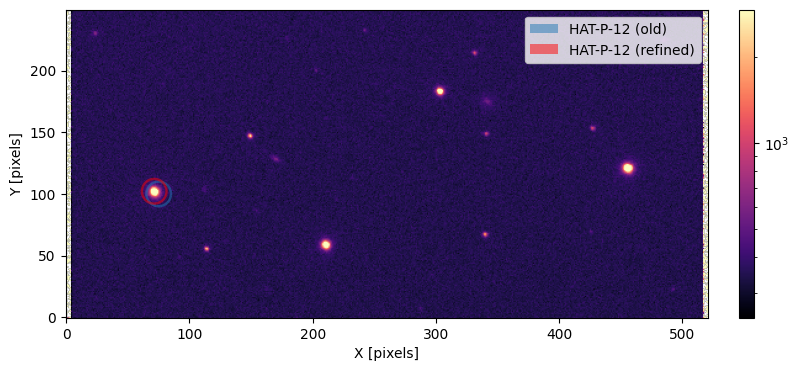

In [130]:
fig, ax = plt.subplots(1,figsize=(10,4))
im1 = plt.imshow(science_corrected,cmap=plt.colormaps['magma'],norm=colors.LogNorm(vmin=vmin, vmax=0.05*vmax),origin='lower')
make_circle_around_star(x_target_initial, y_target_initial, radius=9, thickness=2, label='HAT-P-12 (old)')
make_circle_around_star(x_target_refined, y_target_refined, radius=9, thickness=2, label='HAT-P-12 (refined)', color='r')
plt.colorbar(im1,ax=ax,fraction=0.05,pad=0.04)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
ax.legend()
plt.show()

### Aperture photometry
compute sky flux and subtract.

All radii, from largest to smallest:
- outer radius: used for sky
- inner radius: inner limit for the sky but also for the centroid (small contribute from the star, the wings)
- aperture (< inner radius): radius over wich we perform integration of the flux (large contribute from the star, central part -> 95% of the light)

Choose size in order to don't have flux of the star between inner and outer radius.

In [131]:
# flux within the annulus 
outer_radius = 30

# Selection of the pixels within the annulus
annulus_sel = (target_distance > inner_radius) & (target_distance <= outer_radius)

# We compute the sum of the total flux within the annulus.
total_flux = np.nansum(science_corrected*annulus_sel) 

# We compute the sum of the flux along each axis, within the annulus.
flux_x = np.nansum(science_corrected*annulus_sel, axis=0) 
flux_y = np.nansum(science_corrected*annulus_sel, axis=1) 

# We use the nansum function to avoid problems with the overscan region
sky_flux_average = np.sum(science_corrected[annulus_sel])/np.sum(annulus_sel)
sky_flux_median = np.median(science_corrected[annulus_sel])

print('Number of pixels included in the annulus', np.sum(annulus_sel))
print('Average sky flux', sky_flux_average)
print('Median sky flux', sky_flux_median)

sky_flux_error = np.sqrt(np.sum(science_corrected_error[annulus_sel])**2/np.sum(annulus_sel)**2)
print('Sky flux error', sky_flux_error)

Number of pixels included in the annulus 2206
Average sky flux 355.42130361466565
Median sky flux 354.71816172024864
Sky flux error 0.05830825862085634


/tmp/ipykernel_6801/1421266773.py:8: RuntimeWarning: invalid value encountered in multiply
  total_flux = np.nansum(science_corrected*annulus_sel)
/tmp/ipykernel_6801/1421266773.py:11: RuntimeWarning: invalid value encountered in multiply
  flux_x = np.nansum(science_corrected*annulus_sel, axis=0)
/tmp/ipykernel_6801/1421266773.py:12: RuntimeWarning: invalid value encountered in multiply
  flux_y = np.nansum(science_corrected*annulus_sel, axis=1)


Corrected flux of the target (subtract sky and propagate error)

-110.6175749800444 58408.97021112754


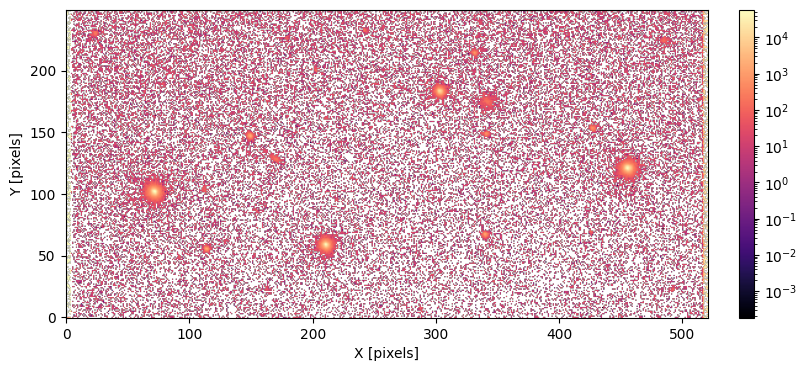

In [132]:
science_sky_corrected = science_corrected - sky_flux_average
science_sky_corrected_error = np.sqrt(science_corrected_error**2 + sky_flux_error**2)

vmin = np.amin(science_sky_corrected[:,15:-15])
vmax = np.amax(science_sky_corrected[:,15:-15])

print(vmin, vmax)

fig, ax = plt.subplots(1,figsize=(10,4))
im = plt.imshow(science_sky_corrected,cmap=plt.colormaps['magma'],origin='lower',norm=colors.LogNorm(vmax=vmax))
plt.colorbar(im,ax=ax,fraction=0.05,pad=0.04)
ax.set_xlabel('X [pixels]')
ax.set_ylabel('Y [pixels]')
plt.show()

Find the right aperture radius, the one that gives 95% of the star flux

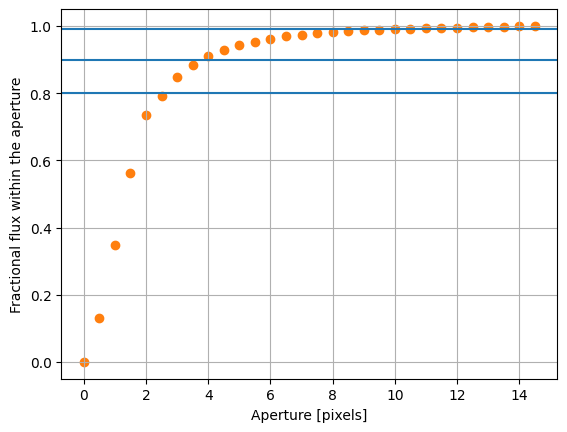

In [148]:
radius_array = np.arange(0, inner_radius +1., 0.5)
flux_vs_radius = np.zeros_like(radius_array)
# inner_radius = 14
# print(inner_radius)

# ma è così arbitraria la scelta del raggio interno per il total flux???
total_flux_selection = (target_distance <= inner_radius)
total_flux = np.sum(science_sky_corrected[total_flux_selection])

for ii, aperture_radius in enumerate(radius_array):
    aperture_selection = (target_distance < aperture_radius)
    flux_vs_radius[ii] = np.sum(science_sky_corrected[aperture_selection])/total_flux

plt.figure()

plt.axhline(0.80)
plt.axhline(0.90)
plt.axhline(0.99)
plt.scatter(radius_array, flux_vs_radius, c='C1')
plt.grid()

plt.xlabel('Aperture [pixels]')
plt.ylabel('Fractional flux within the aperture')
plt.show()
